# Credit card default: gradient boosting (XGBoost)

Gradient boosting builds a sequence of small decision trees. Each new tree is fitted to the gradient of the log-likelihood of the current model (roughly, its remaining errors), and its predictions are added on with a small weight (the learning rate). Trees handle thresholds such as "2 or more months late" and interactions natively, which is why they are often the strongest models on tabular data.

The notebook starts from a **baseline**: the 44 original candidate features plus the 10 behaviour features (54), with learning rate 0.05, trees of depth 4 and a minimum leaf size of 5 (the best of a small grid search). It then tries to improve it one step at a time:

1. **Tree features**: 14 features that combine columns (unpaid amounts, six-month summaries, lateness streaks), since a tree can only split on one column at a time.
2. **Monotone constraints**: predicted risk may only go up with lateness and only go down with payments.
3. **Lateness codes as categories**: −2, −1 and 0 mean different things (no balance, paid in full, paid the minimum), not "less late".
4. **Random search** over the tree settings and regularization.
5. **A lower learning rate** (0.02 instead of 0.05) with more trees.
6. **Averaging 5 seeds**.
7. **LightGBM and CatBoost** as alternative boosting libraries.

**Repeated cross-validation.** The differences being measured are small (log-likelihood changes of ~0.001), so one 5-fold split is too noisy to choose between them. Every step is scored on 5 folds × 3 different shufflings of the development set (15 fits). The first shuffling is the same as in the other notebooks. A step is kept only if it improves the cross-validated log-likelihood. The test set is used once, at the end.

In [1]:
import os
import subprocess
import sys
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # silence CMU font-weight warnings

CURATED = '../data/curated/credit_default.csv'
PLOTS = '../plots/gradient_boosting'
os.makedirs(PLOTS, exist_ok=True)
MONTHS = ['sep', 'aug', 'jul', 'jun', 'may', 'apr']

plt.style.use(['science', 'no-latex', 'grid'])
plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.family': 'sans-serif', 'font.sans-serif': ['CMU Sans Serif'],
    'mathtext.fontset': 'custom', 'mathtext.rm': 'CMU Sans Serif',
    'mathtext.it': 'CMU Sans Serif:italic', 'mathtext.bf': 'CMU Sans Serif:bold',
    'axes.unicode_minus': False, 'axes.formatter.use_mathtext': False,  # CMU has no Unicode minus glyph
})
ROUNDS, N_SEARCH, SEEDS = 5000, 30, range(5)       # max trees, random-search size, seeds to average
LGB_ROUNDS, CB_ROUNDS = 3000, 1500

## Data
Same split as the other notebooks.

In [2]:
if not os.path.exists(CURATED):  # data/ is not in the repo: build it with the EDA notebook
    subprocess.run([sys.executable, '-m', 'nbconvert', '--to', 'notebook', '--execute', '--inplace', 'eda.ipynb'], check=True)
df = pd.read_csv(CURATED)
y = df['default'].values

rng = np.random.default_rng(42)
test_ids = rng.choice(np.arange(1, 30001), size=6000, replace=False)
is_test = df['id'].isin(test_ids).values
test_idx = np.flatnonzero(is_test)

dev_idx = np.flatnonzero(~is_test)
rng.shuffle(dev_idx)
folds = np.array_split(dev_idx, 5)
len(dev_idx), len(test_idx), [len(f) for f in folds]

(23995, 5999, [4799, 4799, 4799, 4799, 4799])

## Features and folds

In [3]:
candidates = (['log_credit_limit', 'age'] + [f'late_{m}' for m in MONTHS]
              + ['late_sep_m2', 'late_sep_m1', 'late_sep_1', 'late_sep_2', 'late_sep_3plus']
              + [f'log_bill_{m}' for m in MONTHS] + [f'log_paid_{m}' for m in MONTHS]
              + [f'util_{m}' for m in MONTHS] + ['months_late', 'credit_balance_months']
              + ['late_x_util', 'late_x_limit', 'months_late_x_util', 'age_x_limit', 'late_sep_x_aug']
              + ['female', 'edu_university', 'edu_high_school', 'edu_other', 'single', 'marital_other'])
candidates += ([f'pay_ratio_{m}' for m in MONTHS[:-1]]
               + ['util_trend', 'late_trend', 'zero_pay_months', 'max_late', 'months_since_late'])
X = df[candidates].values
y_dev, y_test = y[dev_idx], y[test_idx]
d_dev = xgb.DMatrix(X[dev_idx], label=y_dev, feature_names=candidates)
d_test = xgb.DMatrix(X[test_idx], feature_names=candidates)

# the folds are consecutive blocks of the (shuffled) development clients, so their positions within d_dev are too
fold_pos = np.array_split(np.arange(len(dev_idx)), len(folds))
assert all(np.array_equal(dev_idx[p], f) for p, f in zip(fold_pos, folds))
cv_folds = [(np.concatenate(fold_pos[:k] + fold_pos[k + 1:]), fold_pos[k]) for k in range(len(folds))]
len(candidates)
FEATURES_54 = list(candidates)
TREE_FEATURES = ([f'unpaid_{m}' for m in MONTHS[:-1]] + ['log_available_credit', 'util_mean', 'util_max', 'util_std',
                 'total_pay_ratio', 'late_streak', 'months_late_2plus', 'bill_change_sep', 'bill_change_aug'])
FEATURES_68 = FEATURES_54 + TREE_FEATURES
LATE_CODES = [f'late_{m}' for m in MONTHS]
y_dev, y_test = y[dev_idx], y[test_idx]

# 3 repeats of 5 folds, as positions within dev_idx. Repeat 0 = the folds used in every other notebook.
pos = np.arange(len(dev_idx))
cv_folds = []
for r in range(3):
    parts = np.array_split(pos if r == 0 else np.random.default_rng(100 + r).permutation(pos), 5)
    cv_folds += [(np.concatenate(parts[:k] + parts[k + 1:]), parts[k]) for k in range(5)]
first_folds = cv_folds[:5]
assert all(np.array_equal(dev_idx[hold], f) for (_, hold), f in zip(first_folds, folds))
len(FEATURES_54), len(FEATURES_68), len(cv_folds)

(54, 68, 15)

## Scoring
`cv_score` runs XGBoost's cross-validation on the 15 folds, stops adding trees once the average held-out log-loss has not improved for 100 rounds, and reports the cross-validated average log-likelihood (minus the log-loss) and AUC at the best number of trees.

In [4]:
MONOTONE = {'months_late': 1, 'max_late': 1, 'months_late_2plus': 1, 'late_streak': 1, 'zero_pay_months': 1,
            'months_since_late': -1, 'total_pay_ratio': -1, 'log_credit_limit': -1}

def frame(features, idx, categorical):
    X = df.iloc[idx][features].copy()
    if categorical:
        for col in LATE_CODES:
            X[col] = pd.Categorical(X[col], categories=list(range(-2, 9)))
    return X

def dmatrix(cfg, idx, label=True):
    return xgb.DMatrix(frame(cfg['features'], idx, cfg['categorical']), label=y[idx] if label else None,
                       enable_categorical=cfg['categorical'])

def xgb_params(params, cfg):
    p = dict(params)
    if cfg['monotone']:
        p['monotone_constraints'] = {f: s for f, s in MONOTONE.items() if f in cfg['features']}
    return p

def cv_score(params, cfg, folds=cv_folds):
    res = xgb.cv(xgb_params(params, cfg), dmatrix(cfg, dev_idx), num_boost_round=ROUNDS, folds=folds,
                 early_stopping_rounds=100, metrics=['auc', 'logloss'])
    best = int(res['test-logloss-mean'].idxmin())
    return {'log-likelihood': -res['test-logloss-mean'][best], 'AUC': res['test-auc-mean'][best], 'trees': best + 1}

## Steps 1–3: features, monotone constraints, categories
Same settings as the baseline (learning rate 0.05, depth 4, minimum leaf 5). Each change is tried on top of the best configuration so far.

In [5]:
BASE = {'objective': 'binary:logistic', 'eta': 0.05, 'max_depth': 4, 'min_child_weight': 5, 'subsample': 0.8,
        'colsample_bytree': 0.8, 'tree_method': 'hist', 'seed': 0}

cfg = {'features': FEATURES_54, 'monotone': False, 'categorical': False}
best = cv_score(BASE, cfg)
baseline_trees = best['trees']
ladder = [('baseline (54 features)', best['log-likelihood'], best['AUC'], True)]
print(f'{"baseline (54 features)":32s} {best["log-likelihood"]:.4f}  AUC {best["AUC"]:.4f}')
for name, change in [('+ tree features (68)', {'features': FEATURES_68}),
                     ('+ monotone constraints', {'monotone': True}),
                     ('+ lateness codes as categories', {'categorical': True})]:
    trial = {**cfg, **change}
    s = cv_score(BASE, trial)
    kept = s['log-likelihood'] > best['log-likelihood']
    ladder.append((name, s['log-likelihood'], s['AUC'], kept))
    print(f'{name:32s} {s["log-likelihood"]:.4f}  AUC {s["AUC"]:.4f}  {"kept" if kept else "dropped"}')
    if kept:
        cfg, best = trial, s

baseline (54 features)           -0.4234  AUC 0.7897


+ tree features (68)             -0.4225  AUC 0.7910  kept


+ monotone constraints           -0.4228  AUC 0.7908  dropped


+ lateness codes as categories   -0.4227  AUC 0.7911  dropped


## Step 4: random search
30 random combinations of tree depth, leaf size, row and column sampling, and the three regularization terms (`gamma`: minimum gain to make a split; `lambda`, `alpha`: L2 and L1 penalties on the leaf values). To save time each is scored on the first 5 folds; the best 3 are then re-scored on all 15, alongside the current settings.

In [6]:
search_rng = np.random.default_rng(0)
before_search = cv_score(BASE, cfg, folds=first_folds)['log-likelihood']
search = []
for i in range(N_SEARCH):
    p = {**BASE, 'max_depth': int(search_rng.integers(2, 8)),
         'min_child_weight': float(search_rng.choice([1, 2, 5, 10, 20, 50])),
         'subsample': round(float(search_rng.uniform(0.5, 1)), 2),
         'colsample_bytree': round(float(search_rng.uniform(0.3, 1)), 2),
         'gamma': float(search_rng.choice([0, 0.1, 0.5, 1, 2])),
         'lambda': round(float(10 ** search_rng.uniform(-1, 1.5)), 2),
         'alpha': float(search_rng.choice([0, 0.1, 1, 5]))}
    search.append((p, cv_score(p, cfg, folds=first_folds)))

top = sorted(search, key=lambda s: -s[1]['log-likelihood'])[:3]
rescored = [(BASE, best)] + [(p, cv_score(p, cfg)) for p, _ in top]
params, best_search = max(rescored, key=lambda r: r[1]['log-likelihood'])
ladder.append(('+ random search', best_search['log-likelihood'], best_search['AUC'], params is not BASE))
print('chosen:', {k: v for k, v in params.items() if k not in ('objective', 'tree_method', 'seed', 'eta')})
print(f'{"+ random search":32s} {best_search["log-likelihood"]:.4f}  AUC {best_search["AUC"]:.4f}')

chosen: {'max_depth': 3, 'min_child_weight': 2.0, 'subsample': 0.94, 'colsample_bytree': 0.46, 'gamma': 0.0, 'lambda': 0.53, 'alpha': 0.0}
+ random search                  -0.4225  AUC 0.7911


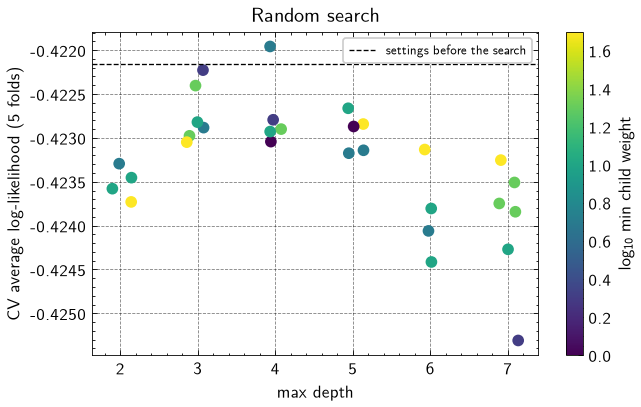

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ll = np.array([s['log-likelihood'] for _, s in search])
depth = np.array([p['max_depth'] for p, _ in search])
sc = ax.scatter(depth + np.random.default_rng(1).uniform(-0.15, 0.15, len(depth)), ll,
                c=[np.log10(p['min_child_weight']) for p, _ in search], cmap='viridis')
ax.axhline(before_search, color='k', linestyle='--', linewidth=0.8, label='settings before the search')
ax.set_xlabel('max depth')
ax.set_ylabel('CV average log-likelihood (5 folds)')
ax.set_title('Random search')
fig.colorbar(sc, label='log$_{10}$ min child weight')
ax.legend(fontsize=8)
plt.savefig(f'{PLOTS}/search.png')
plt.show()

## Step 5: lower learning rate
Smaller steps with more trees usually generalize slightly better.

In [8]:
slow = {**params, 'eta': 0.02}
s = cv_score(slow, cfg)
kept = s['log-likelihood'] > best_search['log-likelihood']
ladder.append(('+ learning rate 0.02', s['log-likelihood'], s['AUC'], kept))
final_params, final_score = (slow, s) if kept else (params, best_search)
n_trees = final_score['trees']
print(f'{"+ learning rate 0.02":32s} {s["log-likelihood"]:.4f}  AUC {s["AUC"]:.4f}  {"kept" if kept else "dropped"}')
print(f'final: {n_trees} trees, learning rate {final_params["eta"]}')

+ learning rate 0.02             -0.4225  AUC 0.7910  dropped
final: 197 trees, learning rate 0.05


## Step 6: averaging 5 seeds
Each seed samples different rows and columns for its trees. Averaging the 5 models' probabilities smooths out that randomness. The threshold catches 65% of defaulters on out-of-fold predictions (first 5 folds).

In [9]:
def fit_predict(fit_idx, pred_idx):
    d_fit, d_pred = dmatrix(cfg, fit_idx), dmatrix(cfg, pred_idx, label=False)
    models = [xgb.train({**xgb_params(final_params, cfg), 'seed': s}, d_fit, n_trees) for s in SEEDS]
    return np.mean([m.predict(d_pred) for m in models], axis=0), models[0]

thresholds = np.arange(0.05, 0.9, 0.01)

def pick_threshold(p):
    recall = [np.sum((p >= t) & (y_dev == 1)) / y_dev.sum() for t in thresholds]
    return round(float(thresholds[np.array(recall) >= 0.65].max()), 2)

def avg_ll(p, yy):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return np.mean(yy * np.log(p) + (1 - yy) * np.log(1 - p))

oof = {'XGBoost tuned': np.full(len(df), np.nan)}
for fit_pos, hold_pos in first_folds:
    oof['XGBoost tuned'][dev_idx[hold_pos]] = fit_predict(dev_idx[fit_pos], dev_idx[hold_pos])[0]
single_seed = cv_score(final_params, cfg, folds=first_folds)['log-likelihood']
print(f'first 5 folds: one seed {single_seed:.4f}, average of {len(SEEDS)} seeds {avg_ll(oof["XGBoost tuned"][dev_idx], y_dev):.4f}')

first 5 folds: one seed -0.4222, average of 5 seeds -0.4223


## Step 7: LightGBM and CatBoost
Two other boosting libraries on the same features and folds:
- **LightGBM** grows trees leaf by leaf (always splitting the leaf that helps most) instead of level by level.
- **CatBoost** uses symmetric trees (the same split at every node of a level) and handles categorical features itself, so the lateness codes are passed as categories.

Settings are sensible defaults rather than tuned. Each is trained for a fixed number of rounds on every fold, the held-out log-loss curves are averaged, and the best number of rounds is chosen, as `xgb.cv` does.

In [10]:
F = cfg['features']

def boost_cv(fit_fn, curve_fn, predict_fn, max_rounds):
    curves, first_models = [], []
    for k, (fit_pos, hold_pos) in enumerate(cv_folds):
        model = fit_fn(dev_idx[fit_pos], dev_idx[hold_pos])
        curves.append(curve_fn(model)[:max_rounds])
        if k < 5:
            first_models.append(model)
    mean_ll = -np.mean(curves, axis=0)
    rounds = int(mean_ll.argmax()) + 1
    p = np.full(len(df), np.nan)
    for model, (_, hold_pos) in zip(first_models, first_folds):
        p[dev_idx[hold_pos]] = predict_fn(model, dev_idx[hold_pos], rounds)
    return mean_ll, rounds, p

LGB = {'objective': 'binary', 'learning_rate': 0.02, 'num_leaves': 15, 'min_child_samples': 50, 'feature_fraction': 0.8,
       'bagging_fraction': 0.8, 'bagging_freq': 1, 'lambda_l2': 1.0, 'verbose': -1, 'seed': 0}

def lgb_fit(fit_idx, hold_idx, rounds=LGB_ROUNDS, record=True):
    rec = {}
    valid = [lgb.Dataset(df.iloc[hold_idx][F], y[hold_idx])] if record else []
    model = lgb.train(LGB, lgb.Dataset(df.iloc[fit_idx][F], y[fit_idx]), rounds, valid_sets=valid,
                      callbacks=[lgb.record_evaluation(rec)] if record else [])
    model.curve = rec['valid_0']['binary_logloss'] if record else None
    return model

lgb_ll, lgb_rounds, oof['LightGBM'] = boost_cv(lgb_fit, lambda m: m.curve,
                                               lambda m, idx, r: m.predict(df.iloc[idx][F], num_iteration=r), LGB_ROUNDS)

def cb_model(rounds):
    return CatBoostClassifier(iterations=rounds, learning_rate=0.05, depth=6, loss_function='Logloss', random_seed=0,
                              verbose=0, cat_features=[c for c in LATE_CODES if c in F], allow_writing_files=False)

def cb_fit(fit_idx, hold_idx):
    model = cb_model(CB_ROUNDS)
    model.fit(df.iloc[fit_idx][F], y[fit_idx], eval_set=(df.iloc[hold_idx][F], y[hold_idx]), use_best_model=False)
    return model

cb_ll, cb_rounds, oof['CatBoost'] = boost_cv(cb_fit, lambda m: m.get_evals_result()['validation']['Logloss'],
                                             lambda m, idx, r: m.predict_proba(df.iloc[idx][F], ntree_end=r)[:, 1], CB_ROUNDS)

ladder.append(('LightGBM', lgb_ll.max(), np.nan, None))
ladder.append(('CatBoost', cb_ll.max(), np.nan, None))
print(f'LightGBM: {lgb_ll.max():.4f} with {lgb_rounds} trees')
print(f'CatBoost: {cb_ll.max():.4f} with {cb_rounds} trees')

LightGBM: -0.4227 with 266 trees
CatBoost: -0.4235 with 236 trees


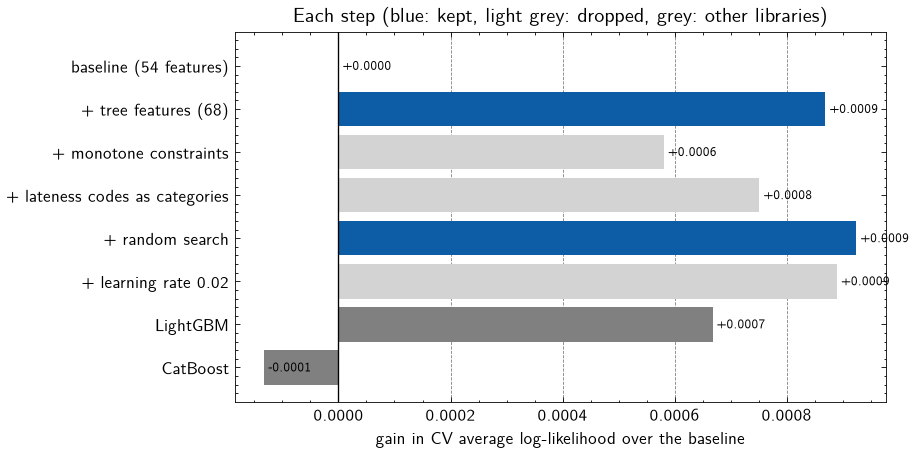

In [11]:
names = [n for n, *_ in ladder]
gains = np.array([v for _, v, *_ in ladder]) - ladder[0][1]
colors = ['grey' if k is None else ('C0' if k else 'lightgrey') for *_, k in ladder]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(names[::-1], gains[::-1], color=colors[::-1])
for i, g in enumerate(gains[::-1]):
    ax.text(g, i, f' {g:+.4f}', va='center', fontsize=8)
ax.axvline(0, color='k', linewidth=0.8)
ax.set_xlabel('gain in CV average log-likelihood over the baseline')
ax.set_title('Each step (blue: kept, light grey: dropped, grey: other libraries)')
ax.grid(axis='y', visible=False)
plt.savefig(f'{PLOTS}/ladder.png')
plt.show()

## Test results
Refit each model on all 24,000 development clients and score the test set once. The baseline (54 features, starting settings) is included for comparison.

In [12]:
def confusion(y, pred):
    tp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1))
    tn = np.sum((pred == 0) & (y == 0))
    return tp, fp, fn, tn

def roc(y, proba):
    y_sorted = y[np.argsort(-proba)]
    tpr = np.concatenate([[0], np.cumsum(y_sorted) / y.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y_sorted) / (1 - y).sum()])
    return fpr, tpr, np.trapezoid(tpr, fpr)

In [13]:
proba, threshold = {}, {}
base_cfg = {'features': FEATURES_54, 'monotone': False, 'categorical': False}

def fit_baseline(fit_idx, pred_idx):
    model = xgb.train(BASE, dmatrix(base_cfg, fit_idx), baseline_trees)
    return model.predict(dmatrix(base_cfg, pred_idx, label=False))

oof['XGBoost baseline'] = np.full(len(df), np.nan)
for fit_pos, hold_pos in first_folds:
    oof['XGBoost baseline'][dev_idx[hold_pos]] = fit_baseline(dev_idx[fit_pos], dev_idx[hold_pos])
proba['XGBoost baseline'] = fit_baseline(dev_idx, test_idx)

proba['XGBoost tuned'], booster = fit_predict(dev_idx, test_idx)
proba['LightGBM'] = lgb_fit(dev_idx, None, rounds=lgb_rounds, record=False).predict(df.iloc[test_idx][F])
cb_final = cb_model(cb_rounds)
cb_final.fit(df.iloc[dev_idx][F], y_dev)
proba['CatBoost'] = cb_final.predict_proba(df.iloc[test_idx][F])[:, 1]
for name in ['XGBoost baseline', 'XGBoost tuned', 'LightGBM', 'CatBoost']:
    threshold[name] = pick_threshold(oof[name][dev_idx])

boot = np.random.default_rng(0)
resamples = [boot.integers(0, len(y_test), len(y_test)) for _ in range(2000)]
boot_auc = {n: np.array([roc(y_test[i], p[i])[2] for i in resamples]) for n, p in proba.items()}
rows = []
for n, p in proba.items():
    tp, fp, fn, tn = confusion(y_test, (p >= threshold[n]).astype(int))
    rows.append({'model': n, 'test AUC': round(roc(y_test, p)[2], 3), 'AUC std. error': round(boot_auc[n].std(), 4),
                 'accuracy at 0.5': round(np.mean((p >= 0.5) == y_test), 3), 'threshold': threshold[n],
                 'defaulters caught': tp, 'false alarms': fp})
results = pd.DataFrame(rows).set_index('model')
for n in ['XGBoost tuned', 'LightGBM', 'CatBoost']:
    gain = boot_auc[n] - boot_auc['XGBoost baseline']
    print(f'AUC gain of {n} over the baseline: {roc(y_test, proba[n])[2] - roc(y_test, proba["XGBoost baseline"])[2]:+.4f}, '
          f'95% interval {np.percentile(gain, 2.5):+.4f} to {np.percentile(gain, 97.5):+.4f}')

results

AUC gain of XGBoost tuned over the baseline: +0.0008, 95% interval -0.0014 to +0.0029
AUC gain of LightGBM over the baseline: +0.0012, 95% interval -0.0009 to +0.0035
AUC gain of CatBoost over the baseline: +0.0020, 95% interval -0.0008 to +0.0047


,test AUC,AUC std. error,accuracy at 0.5,threshold,defaulters caught,false alarms
model,,,,,,
XGBoost baseline,0.786,0.0074,0.821,0.22,855,997
XGBoost tuned,0.786,0.0073,0.825,0.22,854,984
LightGBM,0.787,0.0073,0.822,0.22,851,981
CatBoost,0.788,0.0073,0.822,0.22,848,965


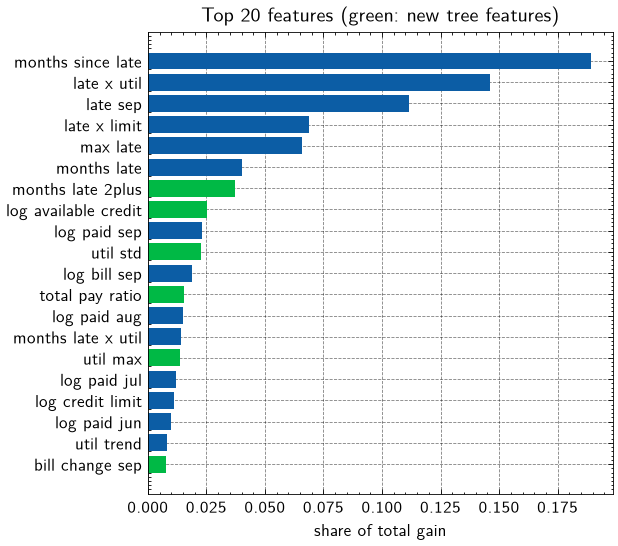

In [14]:
gain = pd.Series(booster.get_score(importance_type='total_gain')).reindex(cfg['features']).fillna(0)
gain = (gain / gain.sum()).sort_values().tail(20)
plt.figure(figsize=(5, 5))
plt.barh(gain.index.str.replace('_', ' '), gain.values, color=['C1' if f in TREE_FEATURES else 'C0' for f in gain.index])
plt.xlabel('share of total gain')
plt.title('Top 20 features (green: new tree features)')
plt.savefig(f'{PLOTS}/feature_importance.png')
plt.show()

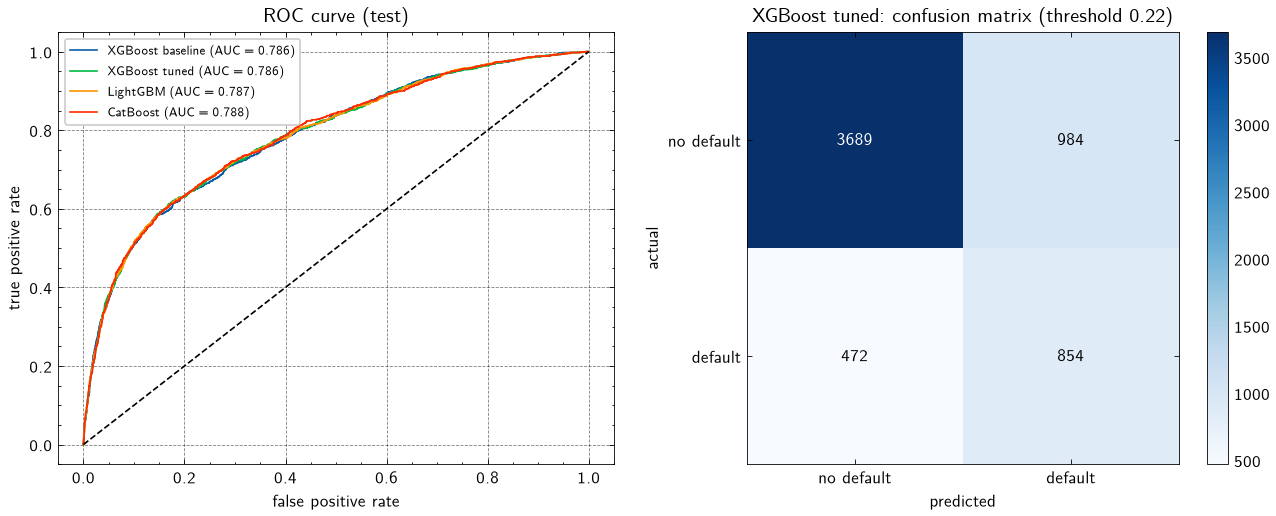

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
for n, p in proba.items():
    fpr, tpr, a = roc(y_test, p)
    ax.plot(fpr, tpr, label=f'{n} (AUC = {a:.3f})')
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate')
ax.set_title('ROC curve (test)')
ax.legend(fontsize=8)

ax = axes[1]
p, t = proba['XGBoost tuned'], threshold['XGBoost tuned']
tp, fp, fn, tn = confusion(y_test, (p >= t).astype(int))
cm = np.array([[tn, fp], [fn, tp]])
im = ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['no default', 'default'])
ax.set_yticks([0, 1], ['no default', 'default'])
ax.grid(False)
ax.minorticks_off()
ax.set_xlabel('predicted')
ax.set_ylabel('actual')
ax.set_title(f'XGBoost tuned: confusion matrix (threshold {t:.2f})')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(f'{PLOTS}/roc_confusion.png')
plt.show()

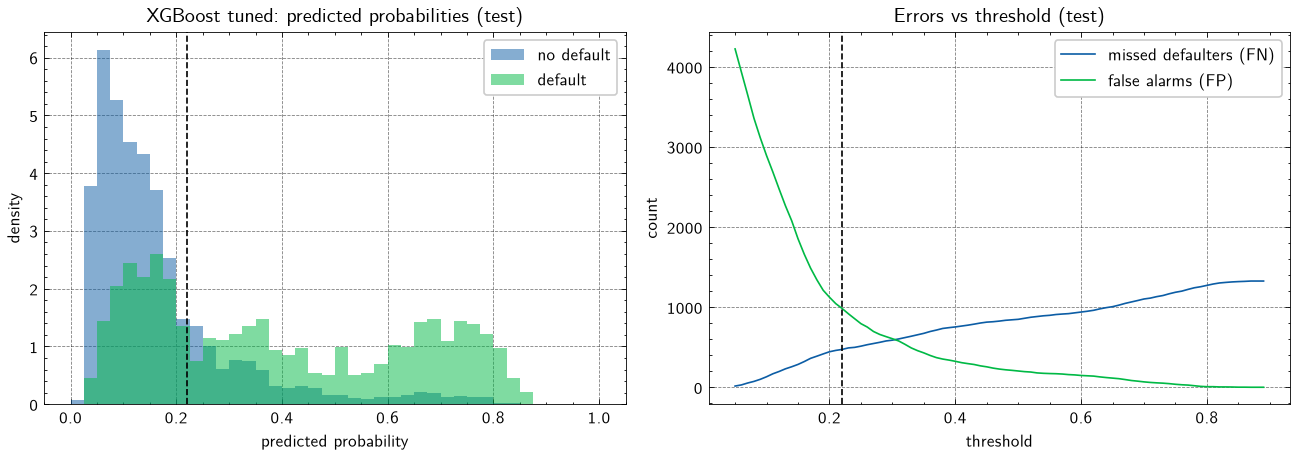

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 1, 41)
p, t = proba['XGBoost tuned'], threshold['XGBoost tuned']
ax = axes[0]
ax.hist(p[y_test == 0], bins=bins, alpha=0.5, density=True, label='no default')
ax.hist(p[y_test == 1], bins=bins, alpha=0.5, density=True, label='default')
ax.axvline(t, color='k', linestyle='--')
ax.set_xlabel('predicted probability')
ax.set_ylabel('density')
ax.set_title('XGBoost tuned: predicted probabilities (test)')
ax.legend()

ax = axes[1]
errs = np.array([confusion(y_test, (p >= th).astype(int)) for th in thresholds])
ax.plot(thresholds, errs[:, 2], label='missed defaulters (FN)')
ax.plot(thresholds, errs[:, 1], label='false alarms (FP)')
ax.axvline(t, color='k', linestyle='--')
ax.set_xlabel('threshold')
ax.set_ylabel('count')
ax.set_title('Errors vs threshold (test)')
ax.legend()
plt.tight_layout()
plt.savefig(f'{PLOTS}/probabilities_errors.png')
plt.show()